# 02 · Collaborative Filtering

Collaborative filtering is one idea stated two ways:

- **User-based:** *find the users most similar to you and copy what they liked.*
- **Item-based:** *find items similar to the ones you liked and recommend those.*

"Similar" is nothing mystical — it is **cosine similarity between rating vectors**.
That is the whole method. In this notebook we draw the similarity out as literal
code, build both variants from scratch, and ask the uncomfortable question: **does
collaborative filtering actually beat the popularity baseline from notebook 01?**

In [1]:
# --- make the notebook runnable from anywhere: find the repo root, add to path, chdir ---
import os
import sys
from pathlib import Path

_root = Path.cwd()
while not (_root / "pyproject.toml").exists() and _root != _root.parent:
    _root = _root.parent
sys.path.insert(0, str(_root))
os.chdir(_root)

%matplotlib inline
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 120)

from src.artifacts import save_figure, save_json
from src.config import get_settings

SETTINGS = get_settings()
print("project root:", _root)
print("seed:", SETTINGS.seed, "| top_k:", SETTINGS.top_k)

project root: /workspaces/recommender_101
seed: 42 | top_k: 10


In [2]:
from src.data.ratings import item_popularity, load_movielens
from src.evaluation.ranking import evaluate_ranking, recall_at_k
from src.evaluation.splits import leave_last_out
from src.recommenders.item_knn import ItemKNNRecommender
from src.recommenders.popularity import PopularityRecommender
from src.recommenders.similarity import topk_cosine
from src.recommenders.user_knn import UserKNNRecommender

data = load_movielens()
matrix, titles = data.matrix, (data.item_titles or [])
n_users, n_items = matrix.shape
split = leave_last_out(
    matrix, n_holdout=SETTINGS.split.n_holdout, min_train=SETTINGS.split.min_train,
    timestamps=data.timestamps, seed=SETTINGS.seed,
)
k = SETTINGS.top_k
evaluated_users = np.array(sorted(split.test_items))
print(f"{n_users} users x {n_items} items | {split.n_evaluated} users evaluated")

610 users x 9724 items | 610 users evaluated


## "Similar" is just cosine similarity — here it is

L2-normalize each item's rating column, take a dot product, and that *is* the
cosine. Below: the items most similar to a well-known, heavily-rated movie. Notice
the neighbours are thematically related even though **no one labelled a genre** —
the similarity comes purely from *who rated what*.

In [3]:
# item-item cosine similarity (top-k neighbours per item) — the same computation
# ItemKNNRecommender uses internally, exposed here.
item_sim = topk_cosine(split.train.T.tocsr(), SETTINGS.knn.n_neighbors)

popularity = item_popularity(split.train)
seed_item = int(np.argmax(popularity))  # the single most-rated movie
row = item_sim.getrow(seed_item).toarray().ravel()
neighbours = np.argsort(row)[::-1][:8]

example = {
    "seed_movie": titles[seed_item] if titles else str(seed_item),
    "nearest_items": [
        {"title": titles[j] if titles else str(j), "cosine": float(row[j])}
        for j in neighbours if row[j] > 0
    ],
}
save_json(example, "02_item_neighbours_example")
pd.DataFrame(example["nearest_items"])

,title,cosine
0,"Shawshank Redemption, The (1994)",0.715494
1,Jurassic Park (1993),0.685707
2,Pulp Fiction (1994),0.682742
3,Braveheart (1995),0.636381
4,"Silence of the Lambs, The (1991)",0.634402
5,Apollo 13 (1995),0.621048
6,"Matrix, The (1999)",0.609460
7,Mrs. Doubtfire (1993),0.608391


## Build both variants and score them against popularity

Same honest protocol as notebook 01: hold out each user's most recent items, rank
the catalog, score with ranking metrics.

In [4]:
models = {
    "popularity": PopularityRecommender(),
    "user_knn": UserKNNRecommender(n_neighbors=SETTINGS.knn.n_neighbors),
    "item_knn": ItemKNNRecommender(n_neighbors=SETTINGS.knn.n_neighbors),
}
scores = {}
recs20 = {}
for name, model in models.items():
    model.fit(split.train)
    recs20[name] = model.recommend_all(k=20)
    scores[name] = evaluate_ranking(recs20[name][:, :k], split.test_items, k)

board = pd.DataFrame(scores).T[["precision@k", "recall@k", "ndcg@k", "map"]]
save_json(board, "02_cf_metrics")
board.round(4)

,precision@k,recall@k,ndcg@k,map
popularity,0.0072,0.0361,0.0209,0.0120
user_knn,0.0123,0.0615,0.0356,0.0210
item_knn,0.0138,0.0689,0.0400,0.0236


## The honest result

Here is the twist people do not expect to run *both* ways. On **accuracy**
metrics, neighbourhood CF genuinely **does beat** popularity — personalization
works. But hold the celebration:

- the absolute margins are modest, and whether user-based or item-based wins
  flips depending on the metric and `k` (below);
- both still lean heavily on recommending broadly-liked items;
- and notebook 04 will show popularity claws it all back on **coverage and
  diversity**, which accuracy hides.

So the real lesson is not "CF wins" or "popularity wins" — it is *which metric,
and for which users*.

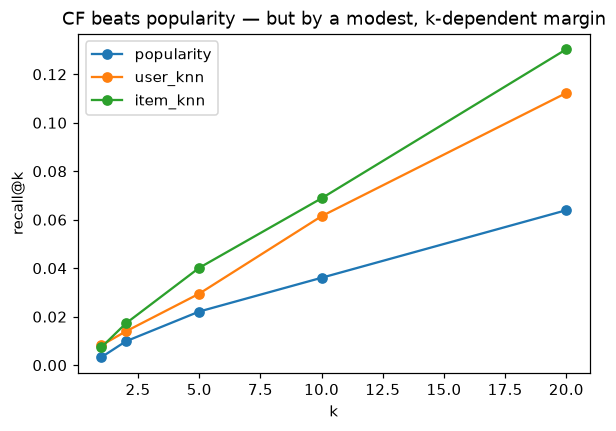

PosixPath('/workspaces/recommender_101/outputs/data/02_recall_vs_k.json')

In [5]:
ks = [1, 2, 5, 10, 20]
curve = {
    name: [np.mean([recall_at_k(recs20[name][u], split.test_items[u], kk) for u in evaluated_users])
           for kk in ks]
    for name in models
}
fig, ax = plt.subplots(figsize=(6, 4))
for name, ys in curve.items():
    ax.plot(ks, ys, marker="o", label=name)
ax.set_xlabel("k")
ax.set_ylabel("recall@k")
ax.set_title("CF beats popularity — but by a modest, k-dependent margin")
ax.legend()
save_figure(fig, "02_recall_vs_k")
plt.show()
save_json({"k": ks, **curve}, "02_recall_vs_k")

## The weakness, shown not asserted: sparsity

Collaborative filtering needs neighbours, and neighbours need overlap. Split the
evaluated users into quartiles by how many ratings they have in training: CF's
advantage over popularity is concentrated among **active** users and **collapses
toward popularity for sparse users**. That same failure, taken to the limit — a
user with *no* history — is the cold-start problem of notebook 05.

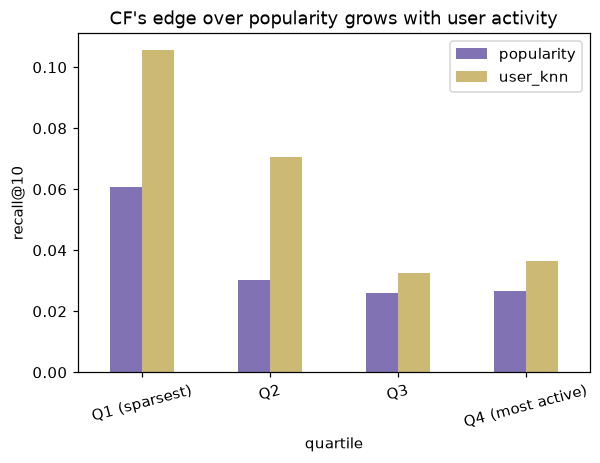

,popularity,user_knn
quartile,,
Q1 (sparsest),0.0609,0.1058
Q2,0.0302,0.0705
Q3,0.0260,0.0325
Q4 (most active),0.0265,0.0364


In [6]:
activity = np.asarray((split.train > 0).sum(axis=1)).ravel()[evaluated_users]
quartiles = pd.qcut(activity, 4, labels=["Q1 (sparsest)", "Q2", "Q3", "Q4 (most active)"])

rows = []
for q in quartiles.categories:
    users_q = evaluated_users[np.asarray(quartiles == q)]
    row = {"quartile": q}
    for name in ["popularity", "user_knn"]:
        row[name] = float(np.mean([recall_at_k(recs20[name][u], split.test_items[u], k) for u in users_q]))
    rows.append(row)
by_activity = pd.DataFrame(rows).set_index("quartile")
save_json(by_activity, "02_cf_by_activity")

fig, ax = plt.subplots(figsize=(6, 4))
by_activity.plot(kind="bar", ax=ax, color=["#8172B3", "#CCB974"])
ax.set_ylabel(f"recall@{k}")
ax.set_title("CF's edge over popularity grows with user activity")
ax.tick_params(axis="x", rotation=15)
save_figure(fig, "02_cf_by_activity")
plt.show()
by_activity.round(4)

**Next:** [03 · Matrix Factorization](03_matrix_factorization.ipynb) — compress the
ratings table into learned taste embeddings, watch it recover *planted* structure,
and meet the famous gap between predicting ratings well and ranking well.